# Assignment 3: Motion Autoencoder

In this assignment, you will implement and train an autoencoder for motion generation using the CMU-Mocap dataset. You will develop a simplified version of a motion manifold system capable of learning from motion capture data, synthesizing new movements, and enabling basic motion editing techniques.

Please read the following two papers as they are your reference for your implementation:
* Learning Motion Manifolds with Convolutional Autoencoders, https://www.ipab.inf.ed.ac.uk/cgvu/motioncnn.pdf
* A Deep Learning Framework for Character Motion Synthesis and Editing, https://www.ipab.inf.ed.ac.uk/cgvu/motionsynthesis.pdf

To help you understand motion data representation, here are some valuable resources:

* **CMU Mocap dataset**: https://mocap.cs.cmu.edu/
  * The raw data format may be challenging to interpret directly. For easier use, download the BVH format (which our dataloader utilizes): https://github.com/una-dinosauria/cmu-mocap
  * Blender (https://www.blender.org/) can be used to visualize the downloaded BVH files. This will provide a clearer understanding of the human skeleton structure used in the dataset and allow you to visualize the raw motion sequences.
* **Additional reference** (optional): For a deeper exploration of human models, you can examine more motion data in FBX format at: https://www.mixamo.com/#/?page=1&type=Motion%2CMotionPack
  * Note that Mixamo uses a different skeletal structure than our dataset, but it includes human mesh deformation with motion, which BVH data doesn't provide.


This assignment includes substantial starter code in separate Python files to help you get started. To receive credit, please:

* Complete all sections marked with `TODO` comments. Feel free to add code or restructure functions to improve your implementation's flexibility during training.
* Present your results by embedding videos and images in this notebook. You should also answer all questions and complete the write-up sections in this notebook.
* Include all necessary video files, images, and code files in your submission for proper evaluation. **Important**: Do NOT submit model checkpoints as these will unnecessarily increase your submission size.

**Export the completed notebook as a PDF report and submit the PDF.** Videos cannot play in a PDF: include representative still images in the report and submit the actual video files with your notebook and Python code in a ZIP file. Keep all completed outputs; do not include model checkpoints or the downloaded dataset.

**Please reserve enough time for this assignment given the potential amount of time for training.**

In [ ]:
# For you to add video to your submission.
from IPython.display import Video

## Part 1: Familiarize Yourself with the Data (10 pt)

Unlike previous assignments where standard dataloaders were readily available in existing libraries, this assignment requires implementing a custom dataloader for the CMU-Mocap dataset.

We've provided most of the dataloader implementation in `dataloader.py`. Download the preprocessed data from https://utexas.box.com/v/cmu-mocap-cache-2026 and place its cache files in `cmu-mocap/cache/` beside this notebook. The supplied examples use `frame_rate=30`, `window_size=160`, `overlap=0.5`, and both velocity and foot-contact features; these settings require `dataset_fr30_ws160_ol0.5_vel1_fc1.pkl`. Keep the downloaded filename unchanged. This package supports the cached-data workflow. Rebuilding from raw BVH files additionally requires `read_bvh.py`, which is not included.

### Setup

Keep `AE.py`, `dataloader.py`, `visualization.py`, and `vid/` beside the notebook. Run commands from this directory. Use Python 3 with PyTorch, NumPy, Matplotlib, tqdm, Jupyter, and IPython installed. Video export also requires the FFmpeg executable on your PATH. PCA/t-SNE analysis may use scikit-learn. Complete the relevant TODOs before running `python dataloader.py` or `python AE.py`.

The PDF is a reading copy; Python implementations belong in the supplied `.py` files. Your notebook should show your figures, videos, and written answers.

For this part, you need to implement data normalization in the dataloader. There are two sets of TODOs in the file:

1. First, compute appropriate statistics for normalizing your data based on the entire dataset
2. Second, implement the normalization procedure in the `__getitem__` function where the dataloader retrieves one motion window (the DataLoader groups windows into batches)

Upon successful completion of this section, you should be able to visualize up to four sample motion sequences by running `python dataloader.py`.

Important notes:
* There are multiple approaches to normalizing motion data. You are free to choose any method that produces reasonable training results in the subsequent sections.
* Include visualizations of your **normalized motion** sequences in your submission for this part, following the example format below.

In [ ]:
# Replace with your own video file.
Video('./vid/sample_0_normalized.mp4', embed=True, width=480)

In [ ]:
Video('./vid/sample_1_normalized.mp4', embed=True, width=480)

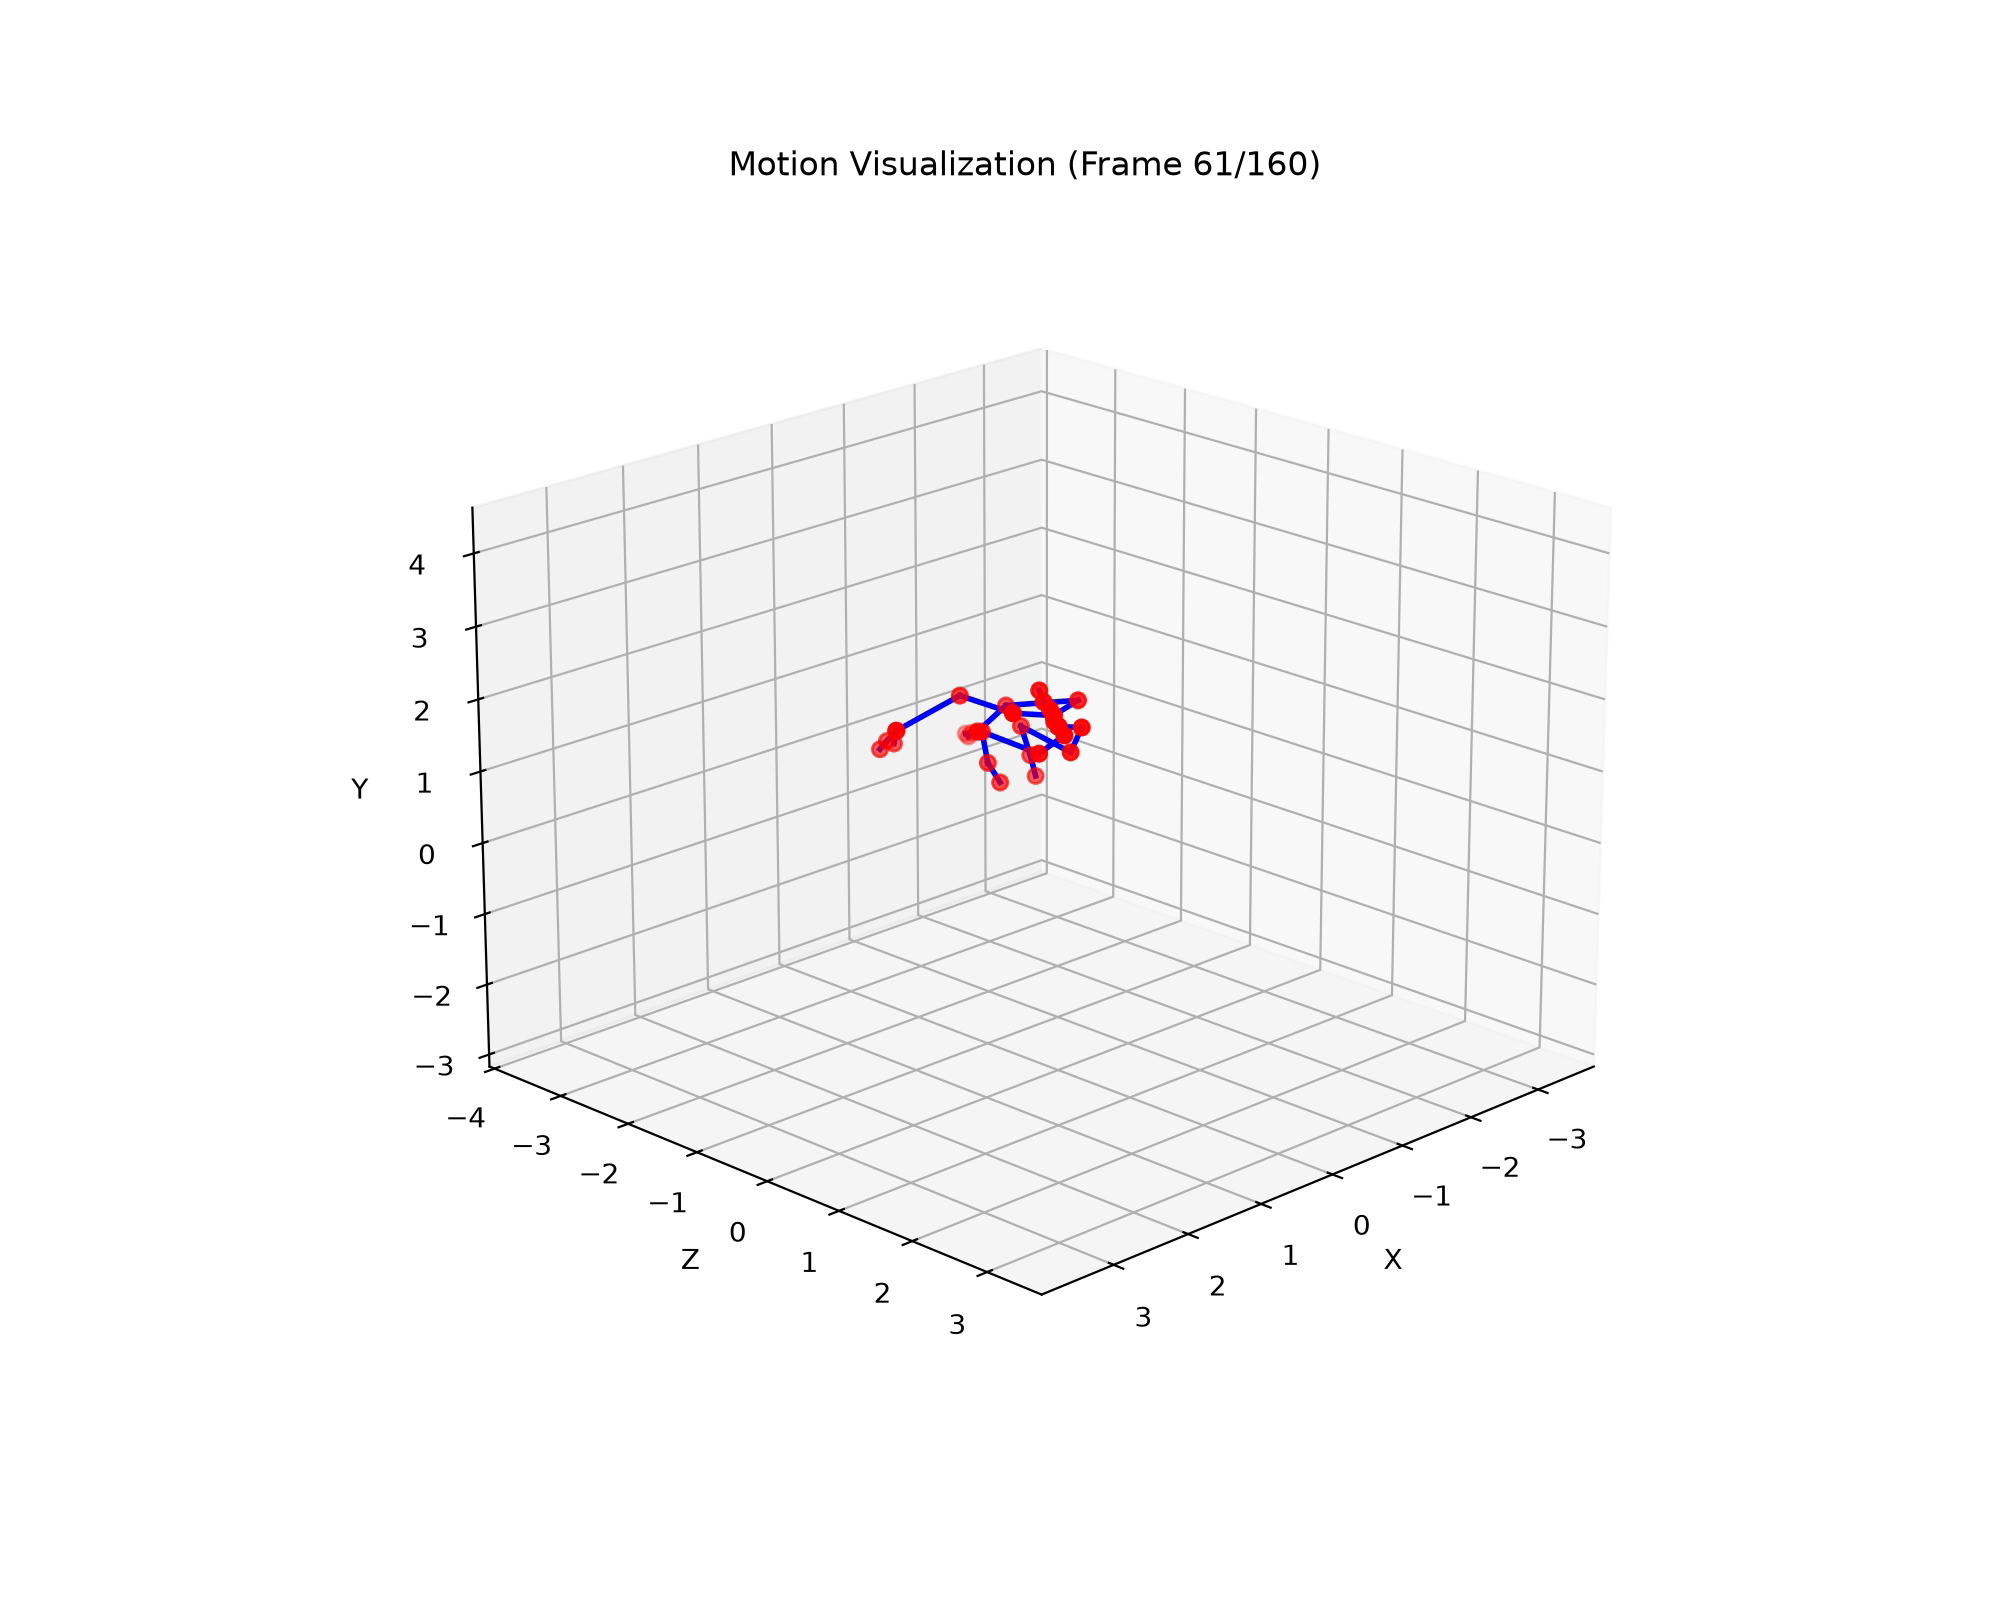
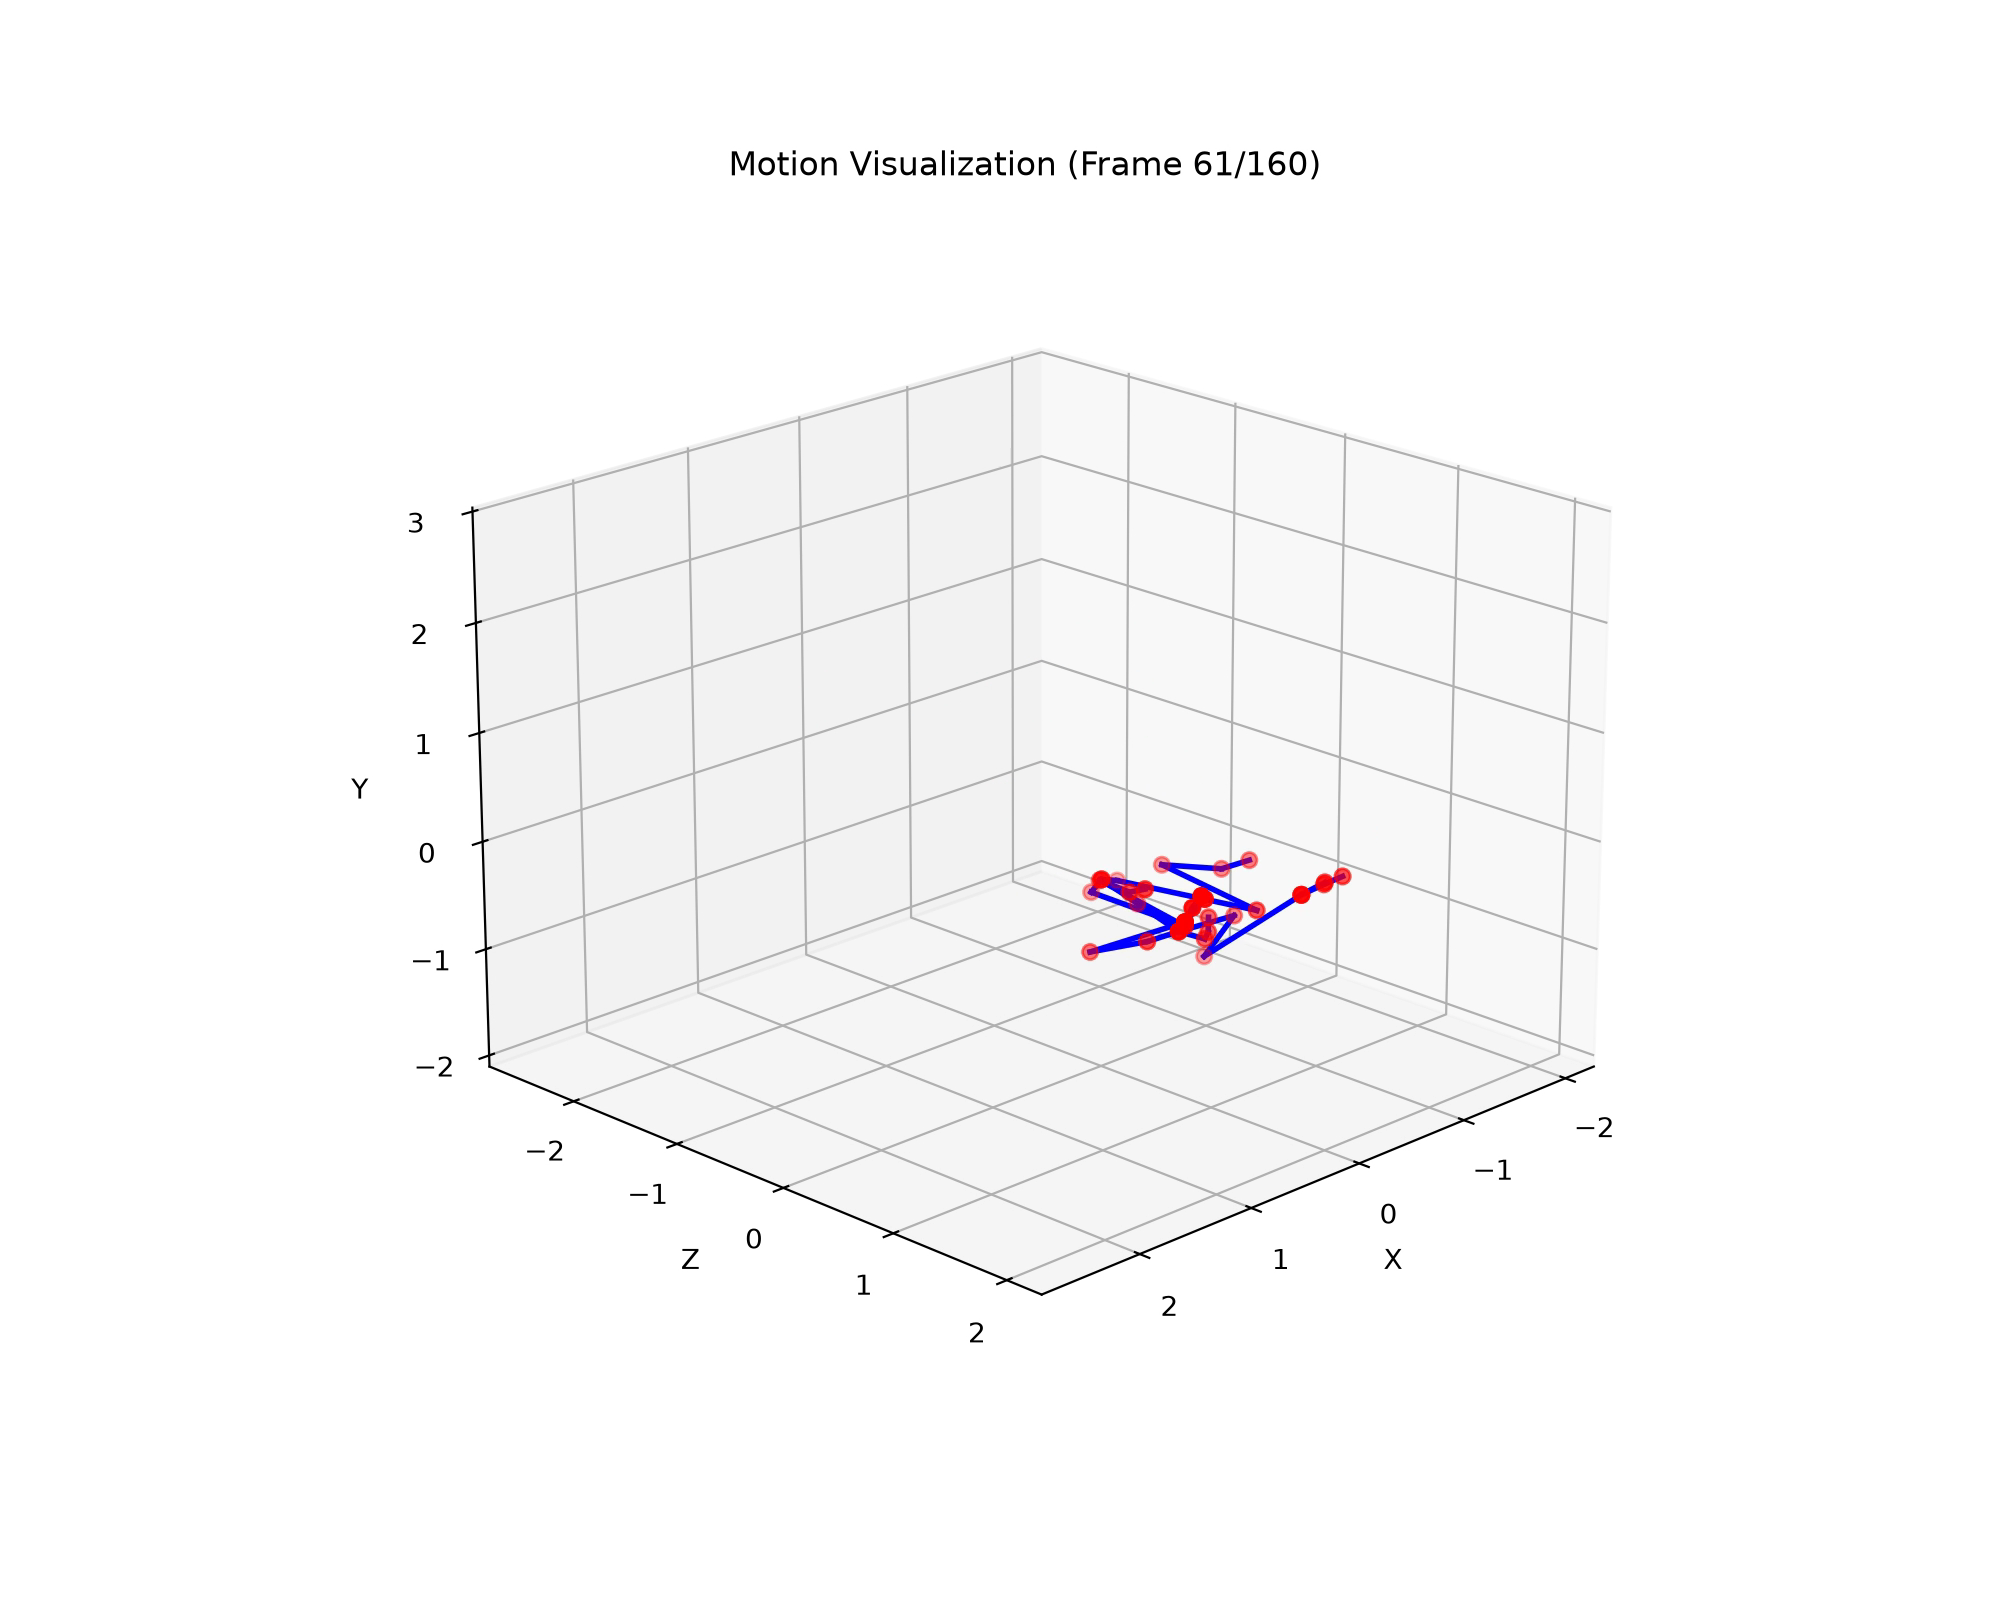

## Part 2: Motion Manifold Learning (45 points)

In this section, you will implement the neural network architecture and training methodology described in the reference paper to learn a motion manifold.

### Convolutional Autoencoder Architecture (15 points)

1. Implement the convolutional autoencoder following the architecture detailed in one of the reference papers in `MotionAutoencoder`.
2. Develop both the encoding and decoding operations that will allow the network to compress motion data into a lower-dimensional manifold representation and then reconstruct it.

### Training Procedure (30 points)

1. Implement the training procedure in `MotionManifoldTrainer` for your autoencoder, carefully considering the appropriate loss function(s) to use for motion data.
2. Generate and include training curves using the visualization template provided in the starter code.

Important considerations:
1. The reference paper was published several years ago when neural network implementations were often manually coded with custom operations. You'll need to adapt these concepts to modern PyTorch conventions and standard operations. Some training parameters may require adjustment to work effectively with contemporary deep learning frameworks.
2. Your submission for this part should include clear visualizations of your training curves showing loss change over time.

TODO: Add your training-curve figures and a brief description of your training settings.

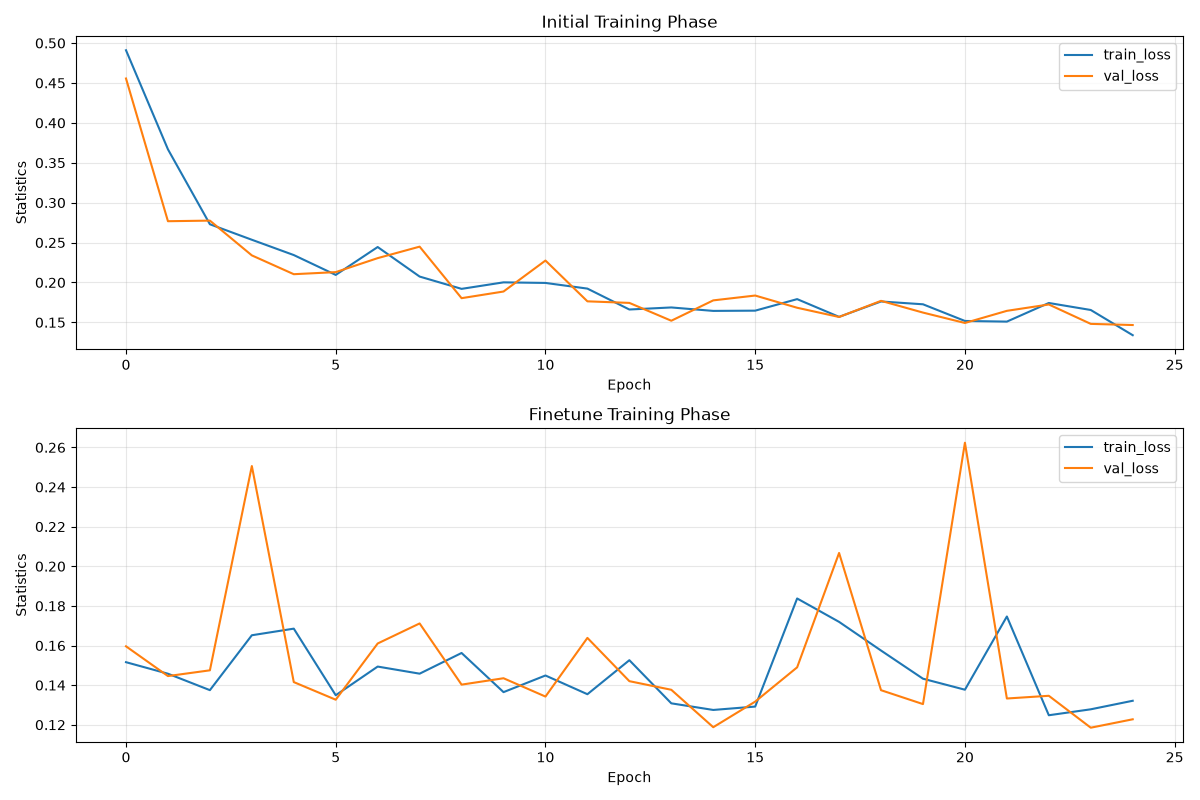

**Training settings**
- **Input:** 160-frame windows (30 fps) with 117 channels: 38 joints x 3 local positions, plus root XZ translational velocity and Y rotational velocity. Positions and velocities are normalized.
- **Architecture:** the encoder has 3 blocks of Conv1d -> ReLU -> MaxPool(2), with 117 -> 128 -> 192 -> 256 channels and kernel widths 25 / 15 / 9.  The decoder mirrors it with linear Upsample(2) -> Conv1d (256 -> 192 -> 128 -> 117), with ReLU between layers and a linear output layer.
- **Loss:** MSE reconstruction of all 117 normalized channels, plus 0.01 x the mean absolute activation of the hidden units.
- **Results:** validation MSE fell from 0.456 after the first epoch to 0.147 at the end of phase 1, and to a best of 0.119 during fine-tuning. Fine-tuning on clean inputs at the same learning rate is noisier: there are occasional validation spikes, and a lower fine-tuning learning rate would likely smooth them out. The final model has a mean-squared reconstruction error of about 0.003 m² per coordinate, roughly 5 cm per coordinate.

## Part 3: Motion Synthesis (30 points)

### Motion Interpolation (15 points)

Implement the function `MotionManifoldSynthesizer.interpolate_motions` that creates transitions between different motions using the learned manifold. This function should accept two motion sequences sampled from the dataset and generate an interpolated motion that blends naturally between them. You can visualize your results using the provided `visualize_interpolation` function.

Your submission for this section should include at least two video examples demonstrating motion interpolation between different movement types.

In [ ]:
# TODO: Display at least two motion-interpolation videos.
import subprocess
import numpy as np
import torch
from IPython.display import Image, display
from dataloader import CMUMotionDataset
from AE import MotionManifoldSynthesizer
from visualization import visualize_interpolation, visualize_motion_comparison

dataset = CMUMotionDataset(data_dir="./cmu-mocap", frame_rate=30, window_size=160, overlap=0.5)
synth = MotionManifoldSynthesizer("./output/ae/models/motion_autoencoder.pt", dataset)

speeds = np.array([np.linalg.norm(dataset.motion_data[f]["trans_vel_xz"][s:s + 160], axis=1).mean() for f, s in dataset.windows])
order = np.argsort(speeds)
idle = int(order[len(order) // 50])
walk = int(np.argmin(np.abs(speeds - 1.3)))
run = int(np.argmin(np.abs(speeds - 3.0)))
for name, i in [("idle", idle), ("walk", walk), ("run", run)]:
    print(f"{name}: window {i}, {dataset.windows[i][0].split('/')[-1]}, mean root speed {speeds[i]:.2f} m/s")

def still(video_path):
    png = video_path.replace(".mp4", ".png")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-ss", "3", "-i", video_path, "-frames:v", "1", png], check=True)
    display(Image(png, width=700))

t = torch.linspace(0, 1, 20)
for a, b, name in [(walk, idle, "walk_to_idle"), (walk, run, "walk_to_run")]:
    m1 = dataset[a]["positions"].unsqueeze(0)
    m2 = dataset[b]["positions"].unsqueeze(0)
    interpolated = synth.interpolate_motions(m1, m2, t)
    video_path = f"./vid/interp_{name}.mp4"
    visualize_interpolation(m1[0], m2[0], interpolated[0], dataset.joint_parents, video_path)
    display(Video(video_path, embed=True, width=480))
    still(video_path)

### Fixing Corrupt Motion Data (15 points)

Implement the function `MotionManifoldSynthesizer.fix_corrupted_motion` that projects corrupted motion data onto the learned manifold and reconstructs corrected, natural-looking movements. This function should demonstrate the manifold's ability to act as a prior distribution over valid human motion. Use the provided `visualize_motion_comparison` function to create side-by-side comparisons of the corrupted input and your reconstructed output.

Your submission for this section should include at least two video examples showing motion correction from different types of corruptions provided in the starter code.

In [ ]:
# TODO: Display at least two motion-correction videos using different corruptions.
corruptions = [("noise", {"scale": 0.05}), ("zero", {"prob": 0.3}), ("missing", {"joint_idx": 23})]

torch.manual_seed(0)
eval_idx = np.random.default_rng(0).choice(len(dataset), 256, replace=False)
batch = {k: torch.stack([dataset[int(i)][k] for i in eval_idx]) for k in ["positions", "trans_vel_xz", "rot_vel_y"]}
clean = batch["positions"]
_, recon = synth.fix_corrupted_motion(batch)
print(f"{'clean (no corruption)':<22} input MSE 0.00000   output MSE {((recon.cpu() - clean) ** 2).mean():.5f}")
for name, params in corruptions:
    corrupted, fixed = synth.fix_corrupted_motion(batch, name, params)
    print(f"{name:<22} input MSE {((corrupted.cpu() - clean) ** 2).mean():.5f}   output MSE {((fixed.cpu() - clean) ** 2).mean():.5f}")

sample = {k: dataset[walk][k].unsqueeze(0) for k in ["positions", "trans_vel_xz", "rot_vel_y"]}
for name, params in corruptions:
    corrupted, fixed = synth.fix_corrupted_motion(sample, name, params)
    video_path = f"./vid/fix_{name}.mp4"
    visualize_motion_comparison(corrupted[0], fixed[0], dataset.joint_parents, video_path)
    display(Video(video_path, embed=True, width=480))
    still(video_path)

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

idx = np.random.default_rng(1).choice(len(dataset), 2000, replace=False)
features = []
with torch.no_grad():
    for chunk in np.array_split(idx, 8):
        items = [dataset[int(i)] for i in chunk]
        pos = torch.stack([it["positions_normalized_flat"] for it in items])
        vel = torch.stack([torch.cat([it["trans_vel_xz"], it["rot_vel_y"].unsqueeze(-1)], -1) for it in items])
        vel = (vel - torch.tensor(dataset.vel_mean, dtype=torch.float32)) / torch.tensor(dataset.vel_std, dtype=torch.float32)
        x = torch.cat([pos, vel], -1).permute(0, 2, 1).to(synth.device)
        features.append(synth.model.encode(x).mean(-1).cpu().numpy())
features = np.concatenate(features)
root_height = np.array([dataset.motion_data[f]["local_positions"][s:s + 160, 0, 1].mean() for f, s in (dataset.windows[int(i)] for i in idx)])

pca = PCA(2).fit(features)
pc = pca.transform(features)
emb = TSNE(2, random_state=0, init="pca").fit_transform(features)
print("PCA explained variance:", pca.explained_variance_ratio_)
print("corr(PC1, speed) =", np.corrcoef(pc[:, 0], speeds[idx])[0, 1], " corr(PC2, speed) =", np.corrcoef(pc[:, 1], speeds[idx])[0, 1])
print("corr(PC1, root height) =", np.corrcoef(pc[:, 0], root_height)[0, 1], " corr(PC2, root height) =", np.corrcoef(pc[:, 1], root_height)[0, 1])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
s0 = axes[0].scatter(pc[:, 0], pc[:, 1], c=speeds[idx], s=5, cmap="viridis", vmax=np.percentile(speeds[idx], 98))
axes[0].set(title="PCA of hidden units (color: root speed m/s)", xlabel="PC1", ylabel="PC2")
fig.colorbar(s0, ax=axes[0])
s1 = axes[1].scatter(emb[:, 0], emb[:, 1], c=speeds[idx], s=5, cmap="viridis", vmax=np.percentile(speeds[idx], 98))
axes[1].set(title="t-SNE of hidden units (color: root speed m/s)")
fig.colorbar(s1, ax=axes[1])
s2 = axes[2].scatter(emb[:, 0], emb[:, 1], c=root_height, s=5, cmap="coolwarm")
axes[2].set(title="t-SNE of hidden units (color: hip height m)")
fig.colorbar(s2, ax=axes[2])
plt.tight_layout()
plt.savefig("./output/ae/plots/latent_pca_tsne.png", dpi=100)
plt.show()

## Part 4. Analysis Questions (15 pt)

Answer the questions using your own observations from your experiments. The questions are open-ended. An autoencoder is a relatively simple method, so the results will not be perfect.

1. Explain your chosen normalization approach for the motion data. Why did you select this method, and how does it specifically address the challenges of human motion data? What other normalization techniques did you consider, and why did you not choose them?

[Answer]: For joint positions we subtract the **per-joint mean pose** (computed over every frame of every clip) and divide by a **single global standard deviation** shared by all 114 position channels. The root velocities (XZ translation and Y rotation) live in different units (m/s and rad/s, with std about 0.44 and 1.68), so they get their own per-channel mean and std.

- Removing the mean pose centres every channel at zero, so the network models how a pose deviates from a neutral standing pose, not where the joints sit absolutely. This is the normalization Holden et al. used.
- A shared std keeps the relative scale between joints, so a 5 cm error on the hand costs the same as a 5 cm error on the hip. A per-channel z-score would treat them differently.
- The root's local X and Z are exactly 0 after global transforms are removed, so a per-channel std would divide by zero.
- Low-variance joints (e.g. the spine, or fingertip end sites that move rigidly with the hand) would also be blown up by a per-channel std, which amplifies their noise and overweights them in the MSE loss.
- Because the root velocities are scaled separately, the yaw rate cannot dominate the loss.

We also considered three alternatives:
- **Per-channel z-scoring:** rejected because of the zero-variance and over-weighting problems above.
- **Min-max scaling to [-1, 1]:** CMU has acrobatic and outlier clips (cartwheels, jumps) that would squeeze ordinary walking into a small range.
- **Scaling by skeleton height / bone length:** unnecessary, because all CMU clips share the same skeleton.

As the Part 1 videos show, the normalized motion is no longer an upright figure. It is a cluster of deviation vectors around the origin, mostly within about ±2 std.

2. After training your autoencoder, explore and describe the structure of your learned manifold. You can use t-SNE or PCA to visualize the hidden unit space (include one image in your answer).  Are different motion types clustered in particular regions? Can you identify meaningful directions in the latent space that correspond to specific motion attributes (speed, posture, etc.)?

[Answer]: CMU has no motion-type labels, so we encoded 2,000 random windows, averaged the 256 x 20 hidden units over time, and colored the embeddings by two measurable attributes: mean root speed, and mean hip height.

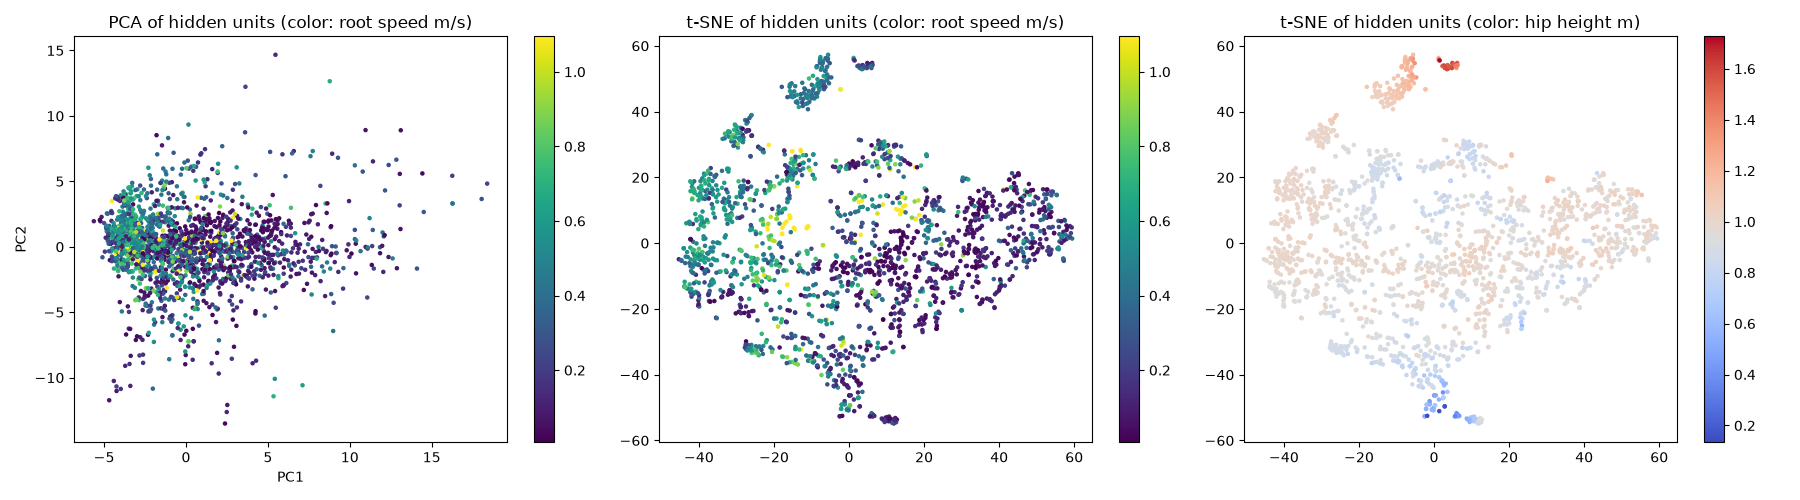

- **The space is clearly organized by posture and locomotion, not by clip.** PC1 and PC2 explain 35% and 18% of the variance.
- **PC2 tracks body height:** it correlates with hip height at r = 0.71. Moving along PC2 goes from crouching, sitting and lying motions (low hips) to standing or elevated poses.
- **PC1 tracks speed, more weakly:** it correlates with root speed at r = -0.33. Stationary windows spread towards positive PC1, while walking and running windows cluster at negative PC1.
- **The t-SNE embedding shows these groups more cleanly.** Fast locomotion (walking and running, green/yellow) forms a region on the left, near-stationary motions (gesturing, standing, reaching) occupy the right, and there are two isolated islands: one with very high hips (jumps or standing on a raised platform) and one with very low hips (lying or sitting on the floor).
- **The clusters are not crisp.** Speed is a mix of directions rather than one axis, and windows from the same clip usually sit close together. This suggests the latent also encodes subject- and style-specific detail.

3. Critically analyze the quality of your interpolated motions. Where does the interpolation succeed or fail? What patterns do you notice about transitions between dissimilar motions versus similar ones?

[Answer]: We interpolate in the hidden-unit space and decode the result. The blend weight t ramps linearly from 0 to 1 across the 20 latent frames, so the output starts as motion 1 and ends as motion 2. We show walk -> idle and walk -> run.

**Where it succeeds:**
- The output is always a coherent, smooth skeleton. The decoder never produces broken limbs or teleporting joints, because every intermediate code decodes through the learned manifold. Averaging joint positions directly does not have this guarantee.
- **Walk -> idle, the similar pair, works best.** The idle pose is close to the mean pose, so the arm and leg swings shrink gradually and the character settles into standing.
- The 25-frame kernels in the first layer also smooth the transition in time, so there is no visible pop.

**Where it fails:**
- **Walk -> run, the dissimilar pair:** the two windows are not phase-aligned (the left foot may be forward in one while the right foot is forward in the other). Halfway through the blend the out-of-phase leg swings partly cancel. The result is a shuffling, reduced-stride gait with foot sliding, not a convincing jog. The torso lean and arm carriage of the run also show up only near the end.
- **Missing velocities:** the interpolation inputs contain positions only (velocity channels set to the dataset mean), so the root speed does not change smoothly between the two motions.
- Linear blending in this space works well between motions that lie close together on the manifold, but between dissimilar ones it produces averages, not true transitions. Time-warping or phase alignment, or interpolating only in a learned subspace, would be needed.

4. For the corrupted motion reconstruction task, analyze which types of corruption your system handles well versus poorly. What does this tell you about the properties of your learned manifold?

[Answer]: Results on 256 random windows (MSE in m² against the clean motion; plain reconstruction of clean input already has an error of 0.0030):

| Corruption | Input MSE | Output MSE |
|---|---|---|
| Gaussian noise, σ = 5 cm | 0.0025 | 0.0030 |
| 30% of values set to 0 | 0.0950 | 0.0298 |
| Missing joint (left hand zeroed) | 0.0090 | 0.0041 |

- **Missing joint: handled well.** Error drops by more than half. The left hand is placed plausibly at the end of the forearm and follows the arm swing, because the manifold has learned the strong correlations between neighboring joints over time. The missing information is predictable from the rest of the body.
- **Random zeros: handled only partly.** Error drops about 3x and the gross skeleton jitter disappears. However, the reconstructed figure is visibly compressed or shorter, because many inputs are pulled towards 0 at once. This corruption is far from anything seen in training (our denoising phase only dropped 10% of normalized values, i.e. moved them to the mean, not to absolute zero). A single projection therefore lands on a nearby but shrunk pose. Iterating the projection, or training with this exact corruption, would help.
- **Gaussian noise: visually smoother, but no gain in MSE.** The output is smooth and the frame-to-frame jitter is removed, yet the output error (0.0030) equals the reconstruction error on clean input. The autoencoder acts as a temporal and spatial low-pass filter: it removes high-frequency noise, but its own smoothing bias (it slightly damps fast limb motion) is about as large as the small 5 cm noise.

**What this says about the manifold:** it is smooth and low-dimensional, and it encodes correlations between joints and over time. This makes it a good prior for structured, local corruption (missing joints, isolated dropouts). The cost is fine detail: it removes high frequencies along with the noise, and it does not fully correct corruption far from the training distribution in one pass.

## Extra Credit: Advanced Motion Synthesis and Editing (20 points)

In this optional extra credit section, you'll implement more sophisticated motion synthesis techniques and potentially extend your model architecture to achieve these advanced tasks.

### Motion Completion (10 points)

For this task, you'll develop a method to complete partially specified motion sequences. Given a motion with missing frames, your system should intelligently fill in the gaps while maintaining natural movement characteristics and continuity.

You need:
- Develop a method to mask out and fill missing segments in motion sequences
- Ensure smooth transitions between existing and synthesized motion
- Leverage your trained motion manifold to generate plausible completions

Your submission should:
- Provide at least two examples of filling gaps in the middle of motion sequences
- Provide at least two examples of extending incomplete motions by synthesizing the ending frames
- For each visualization, you need to show the input and output side-by-side
- Include a short analysis of your approach and the quality of your results

### Motion Editing (10 points)

For this task, you'll implement the style transfer technique described in "A Deep Learning Framework for Character Motion Synthesis and Editing." This will allow you to transfer the style characteristics of one motion to another while preserving the content of the target motion.

You need to develop the method to add constraints to the trained autoencoder.

Your submission should:
- Provide at least three examples of motion editing results between different motion types. Each visualization should include the original content motion, the reference motion, and your result
- Write a short analysis of your results, discussing successes, limitations, and potential improvements


### Motion Completion results

Left: input with the missing frames removed (shown as zeros). Right: completed motion. Gap examples remove frames 60-99 (1.3 s); extension examples keep only frames 0-109 and synthesize frames 110-159.

In [ ]:
known_gap = torch.ones(160, dtype=torch.bool)
known_gap[60:100] = False
known_end = torch.arange(160) < 110

eval_pos = torch.stack([dataset[int(i)]["positions"] for i in eval_idx[:16]])
for name, known in [("gap (frames 60-99)", known_gap), ("extension (frames 110-159)", known_end)]:
    k = np.flatnonzero(known.numpy())
    interp = torch.tensor(np.stack([np.stack([np.interp(np.arange(160), k, f[k, c]) for c in range(f.shape[1])], 1) for f in eval_pos.reshape(16, 160, -1).numpy()]), dtype=torch.float32).reshape(eval_pos.shape)
    projected = synth.complete_motion(eval_pos, known, iterations=0)
    completed = synth.complete_motion(eval_pos, known)
    print(f"{name:<28} MSE on missing frames: interpolation/hold {((interp - eval_pos)[:, ~known] ** 2).mean():.5f}   single projection {((projected - eval_pos)[:, ~known] ** 2).mean():.5f}   latent optimization {((completed - eval_pos)[:, ~known] ** 2).mean():.5f}")

examples = [("gap_walk", walk, known_gap), ("gap_run", run, known_gap), ("extend_walk", walk, known_end), ("extend_run", run, known_end)]
for name, i, known in examples:
    positions = dataset[i]["positions"].unsqueeze(0)
    completed = synth.complete_motion(positions, known)
    masked = positions * known.view(1, -1, 1, 1)
    video_path = f"./vid/complete_{name}.mp4"
    visualize_motion_comparison(masked[0], completed[0], dataset.joint_parents, video_path)
    display(Video(video_path, embed=True, width=480))
    if known.all():
        still(video_path)
    else:
        png = video_path.replace(".mp4", ".png")
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-ss", str((~known).nonzero()[len((~known).nonzero()) // 2].item() / 30), "-i", video_path, "-frames:v", "1", png], check=True)
        display(Image(png, width=700))

**Approach.** The missing frames are first filled with linear interpolation between the neighboring known frames. For an extension, this means holding the last known pose. This initial motion is encoded onto the manifold. The hidden units are then optimized with Adam, so that the decoded motion matches the known frames. The decoder fills the missing frames from the manifold, and the known frames are copied back unchanged. I first tried repeatedly projecting the motion with the autoencoder. That diverged: the error grew past 50 m² after 50 passes.

**Results** (MSE in m² on the missing frames of 16 random windows; stills show a frame from inside the missing segment):

| Task | Interpolation / hold | Single projection | Latent optimization |
|---|---|---|---|
| Gap, frames 60-99 (1.3 s) | 0.0071 | 0.0083 | 0.0087 |
| Extension, frames 110-159 (1.7 s) | 0.0181 | 0.0169 | 0.0167 |

- **Limitations:** the 160-frame window limits how far it can extend. Over long gaps the result drifts towards the average pose, because the decoder blurs high frequencies. Root velocity is not synthesized either.
- **Improvements:** add smoothness and foot-contact constraints, condition on the velocity channels, or train the network explicitly with masked inputs.

### Motion Editing results

Style transfer: starting from the content motion's hidden units, we optimize hidden units H to minimize ||Φ(C) − H||² + s · ||G(Φ(S)) − G(H)||², where G(H) = H Hᵀ / T is the Gram matrix of the hidden units over time (s = 10, Adam, 500 steps, H clamped at 0 to match the ReLU encoder), and decode Φ†(H). Each video shows **left: content motion ("Motion 1")**, **middle: result**, **right: style reference ("Motion 2")**. The panel titles come from the provided `visualize_interpolation` function.

In [ ]:
hip = np.array([dataset.motion_data[f]["local_positions"][s:s + 160, 0, 1].mean() for f, s in dataset.windows])
crouch = int(np.argmin(np.abs(hip - 0.55)))
print(f"crouch: window {crouch}, {dataset.windows[crouch][0].split('/')[-1]}, mean hip height {hip[crouch]:.2f} m, mean root speed {speeds[crouch]:.2f} m/s")

def hand_spread(p):
    return p[0, :, [23, 32]].std(0).norm(dim=-1).mean().item()

for content_i, style_i, name in [(walk, crouch, "walk_crouch_style"), (run, crouch, "run_crouch_style"), (idle, walk, "idle_walk_style")]:
    content = dataset[content_i]["positions"].unsqueeze(0)
    style = dataset[style_i]["positions"].unsqueeze(0)
    result = synth.transfer_style(content, style)
    print(f"{name:<20} hip height content {content[0, :, 0, 1].mean():.2f}  reference {style[0, :, 0, 1].mean():.2f}  result {result[0, :, 0, 1].mean():.2f} | "
          f"hand motion spread content {hand_spread(content):.3f}  reference {hand_spread(style):.3f}  result {hand_spread(result):.3f}")
    video_path = f"./vid/edit_{name}.mp4"
    visualize_interpolation(content[0], style[0], result[0], dataset.joint_parents, video_path)
    display(Video(video_path, embed=True, width=480))
    still(video_path)

**Analysis.** 
The reference labelled "crouch" in the code is the lowest-hip window in the dataset (`144_30`, mean hip height 0.55 m), a crawling / on-all-fours motion.

| Example | Hip height: content / reference / result (m) | Hand motion spread: content / reference / result |
|---|---|---|
| walk + crawl style | 0.89 / 0.55 / 0.75 | 0.323 / 0.141 / 0.150 |
| run + crawl style | 0.88 / 0.55 / 0.72 | 0.251 / 0.141 / 0.112 |
| idle + walk style | 1.03 / 0.89 / 0.95 | 0.116 / 0.323 / 0.113 |

- **Successes:** posture transfers clearly. With the crawl as the style, the walk and the run keep their stepping, but the character becomes hunched and lowered: the hips drop by 0.14-0.16 m, the torso leans forward, and the arm swing shrinks to the reference's level. Because the result is decoded from the manifold, it is always a coherent skeleton. Each edit takes about 0.2 s, since the optimization works only on the hidden units.
- **Limitations:** the Gram matrix captures which hidden channels are active together. It barely captures temporal style. In idle + walk style, the posture shifts slightly towards the walker, but the arms do not start, because the content term keeps the timing of the idle motion. Content and style are not cleanly separated either. In our weight sweep, raising the style weight beyond 10 barely moved the result further, so the content term and the manifold limit how far the motion can be pushed. Our autoencoder was trained on general CMU data with no style labels and only 20 latent frames, and it has no velocity or foot-contact constraints, so the edited motions can show foot sliding.
- **Improvements:** use the deeper network and the feet/trajectory constraints, compute the Gram matrix at several layers, match the root velocity, and use reference clips that differ only in style rather than in action.